Problem-03

Using Python and scikit-learn, generate a binary classification dataset with 500 observations, 6 features, 4 informative features, 1 redundant feature, 2 classes and random_state = last two digits of your roll number
Perform the following:

a. Display the first five observations.
b. Split the data into 70% training and 30% testing sets.
c. Apply Logistic Regression to the training data.
d. Predict the class labels and probability scores for the test data.
e. Construct the confusion matrix.
f. Plot the ROC curve and calculate the AUC.
g. Briefly interpret the obtained AUC value

In [1]:
#Libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,confusion_matrix,roc_curve,roc_auc_score



In [2]:
# Generate dataset
X, y = make_classification(
    n_samples=500,
    n_features=6,
    n_informative=4,
    n_redundant=1,
    n_classes=2,
    random_state=35
)

# Create DataFrame
df = pd.DataFrame(X, columns=[
    'X1', 'X2', 'X3', 'X4', 'X5', 'X6'
])
df['Target'] = y

# 1. Display first five observations
print("First five observations:")
print(df.head())

# Separate input and target
X = df.drop('Target', axis=1)
y = df['Target']


First five observations:
         X1        X2        X3        X4        X5        X6  Target
0 -0.615215  1.229184  0.499970  0.140220  1.611918  0.323640       0
1 -2.108521 -2.357425  0.838488 -1.991371 -1.337021  4.433858       1
2 -1.306759 -1.664129  1.320013 -0.757571  0.721339  2.992541       1
3 -0.427174  0.166193 -0.134515 -1.044087  0.493186  1.068504       0
4  0.687093  1.344298 -0.037370  1.153666  1.538264 -1.873417       0


In [23]:
# (b) Split data: 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=35
)

print("Training size:", X_train.shape[0])
print("Testing size:", X_test.shape[0])

Training size: 350
Testing size: 150


In [24]:
#c. Apply Logistic Regression to the training data.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.6533333333333333


In [25]:
# d. Predict the class labels and probability scores for the test data.
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Predicted class labels:")
print(y_pred)

print("Predicted probabilities for class 1:")
print(y_prob)

Predicted class labels:
[1 0 0 1 0 1 1 0 1 0 0 0 0 1 0 1 0 1 1 1 1 0 1 1 1 1 0 0 0 1 1 1 0 0 0 1 1
 1 0 1 1 1 1 1 0 0 0 0 0 0 0 1 0 1 1 1 0 0 1 1 0 1 1 1 1 0 0 0 1 0 0 1 0 0
 0 0 1 0 0 1 1 1 0 1 1 1 0 1 1 1 1 0 1 0 0 0 0 1 1 1 0 1 0 1 0 0 1 1 1 0 1
 1 0 1 1 1 0 1 1 0 0 0 1 1 0 0 0 0 0 0 1 0 1 1 0 1 0 1 1 0 0 0 1 1 1 1 1 0
 1 0]
Predicted probabilities for class 1:
[0.86699447 0.20503098 0.26341202 0.53589649 0.17922587 0.63933536
 0.61875215 0.15765633 0.66235081 0.24305194 0.44242963 0.35211748
 0.0840011  0.50720168 0.28926732 0.67942466 0.4829895  0.54183367
 0.51720535 0.95654081 0.680444   0.04746279 0.89361742 0.9240509
 0.64551474 0.97079322 0.45175322 0.3524195  0.09907421 0.56931302
 0.53287251 0.53719212 0.42482903 0.20694331 0.48288672 0.82113035
 0.93333376 0.50389197 0.33863412 0.93855561 0.87503485 0.76262946
 0.72920451 0.53015249 0.27265632 0.28682237 0.23701961 0.48655024
 0.37683146 0.37536797 0.08700284 0.81085547 0.23841091 0.89978065
 0.86473826 0.66876666 0.044364

In [26]:
# e. Construct the confusion matrix.
cm=confusion_matrix(y_test,y_pred)
print("confusion_matrix:")
print(cm)

confusion_matrix:
[[45 26]
 [26 53]]


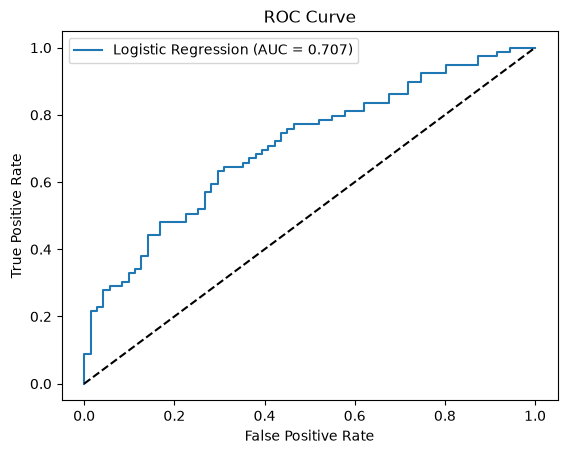

AUC: 0.7072561954002496


In [27]:
# f. Plot the ROC curve and calculate the AUC.
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label='Logistic Regression (AUC = %.3f)' % auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

print("AUC:", auc)

### Interpretation of Logistic Regression Results

The dataset was divided into 350 training observations (70%) and 150 testing observations (30%). The Logistic Regression model achieved an accuracy of **65.33%**, indicating that it correctly classified approximately 65% of the test observations. The AUC value was **0.7073**, suggesting that the model has a reasonable ability to distinguish between the two classes. Overall, the model shows moderate classification performance, but further improvements may be possible through feature selection, parameter tuning, and testing other classification algorithms.